# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; display: inline-block; padding: 20px 30px; margin: 0 auto; line-height: 1.5;">Cutting-Edge Potato Disease Detection: PlantVillage Insights|EfficientNetB3</p>


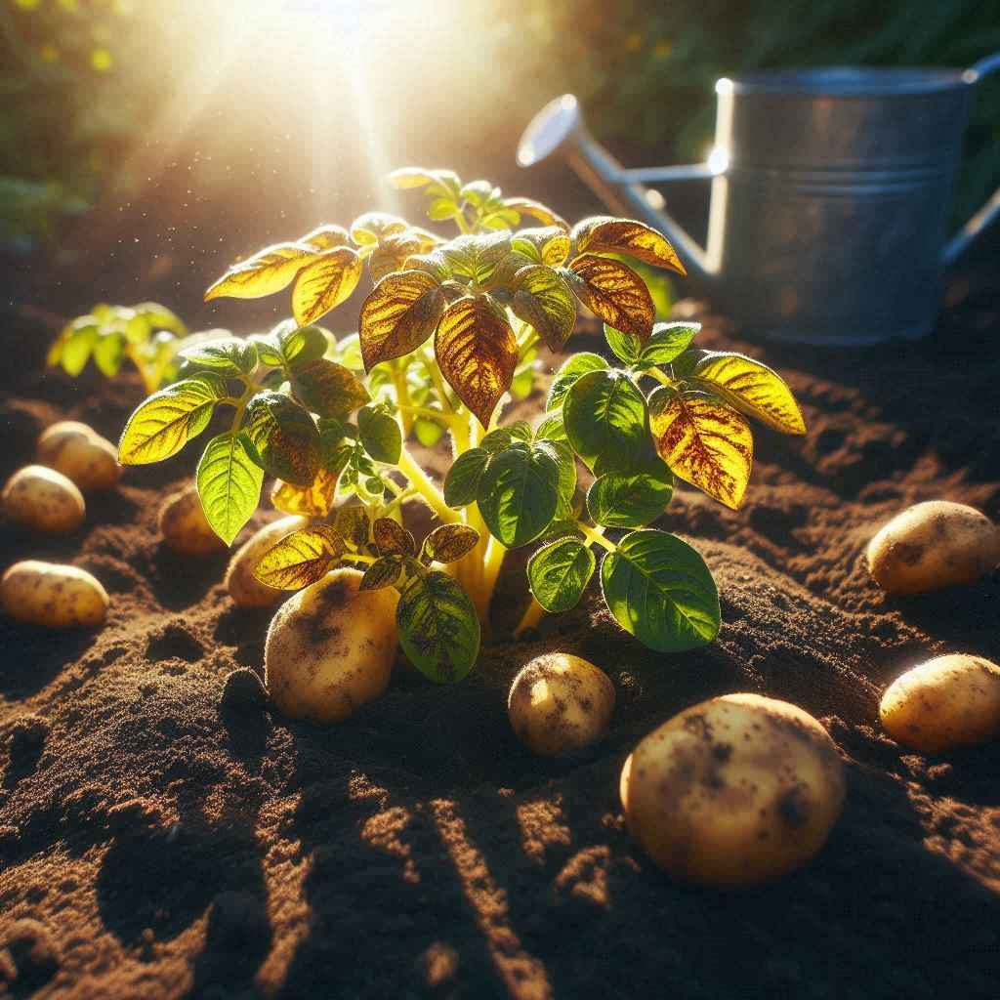

# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">About Dataset</p>

* This is the plant village potato disease Dataset
* This Dataset is a comprehensive collection of images which is categorized into three distinct classes: early blight, late blight, and healthy.
* `Early blight` of potato is caused by the fungus, Alternaria solani, which can cause disease in potato, tomato, other members of the potato family, and some mustards. This disease, also known as target spot, rarely affects young, vigorously growing plants.
* `Late blight` caused by the fungus Phytophthora infestans is the most important disease of potato that can result into crop failures in a short period if appropriate control measures are not adopted.
* `Healthy potatoes:` They're rich in vitamin C, which is an antioxidant and are life-saving food source in early times because the vitamin C prevented scurvy. Another major nutrient in potatoes is potassium, an electrolyte which aids in the workings of our heart, muscles, and nervous system.
* Each class represents a specific condition affecting potato crops
* With this rich dataset, we can explore various images of plant diseases.

# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">Dataset Content</p>

* There are Total 2152 number of Images in Dataset
* The plant village contains 3 folders such as of Class Potato Early_blight, Potato Late_blight and Potato healthy
* The Class Potato Early_blight consists of 1000 number of Images
* The Class Potato Late_blight also consists of 1000 number of Images
* The Potato Healthy consists of 152 number of Images

# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">Aims and Objectives</p>

* This is the plant village potato disease Dataset
* The Aim to take this Dataset is to explore the plant diseases which belongs to the classes such as the Potato late_blight, Potato Early_blight and also the healthy poato plants
* For this I firstly took the overview of the dataset in order to take a look how many number of images in each class has according to this dataset.
* Then I display the images of each class in order to take the insights about the dataset.
* Then I load and Finetune EfficientNetB3 and evlauate the results
* Then I Generate the predictions based on that model

# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">Dataset Link</p>

**Dataset link:** https://www.kaggle.com/datasets/aarishasifkhan/plantvillage-potato-disease-dataset/data

# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">About the notebook</p>


* In this Notebook, we firstly took the overview of the dataset in order to take a look at how many images are in each class and also display the images of each class to gain deep insights about this dataset.
* Then we load and finetune EfficientNetB3 and evaluate the results and generate the predictions based on that.


# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">Import Libraries</p>

In [12]:
import pandas as pd
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt
import os
import random
from PIL import Image
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import img_to_array, load_img
# ignore warnings
import warnings
warnings.filterwarnings("ignore")


# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">Dataset Overview</p>

In [13]:
# Define the path to the dataset and the class folders

dataset_dir = "C:\\Users\\USER\\OneDrive\\Desktop\\Plant\\dataset\\PlantVillage"
class_dirs = ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

# Print overview information
print("Dataset Overview:")
print("=================")

for class_dir in class_dirs:
    class_path = os.path.join(dataset_dir, class_dir)
    num_images = len(os.listdir(class_path))
    print(f"Class: {class_dir}, Number of Images: {num_images}")

# Optionally print sample image filenames
    # print(f"Sample Images: {os.listdir(class_path)[:5]}")  # Print first 5 image filenames
    # print()

# Total number of images in the dataset
total_images = sum(len(os.listdir(os.path.join(dataset_dir, class_dir))) for class_dir in class_dirs)
print(f"Total Number of Images in Dataset: {total_images}")


Dataset Overview:
Class: Potato___Early_blight, Number of Images: 1000
Class: Potato___Late_blight, Number of Images: 1000
Class: Potato___healthy, Number of Images: 152
Total Number of Images in Dataset: 2152


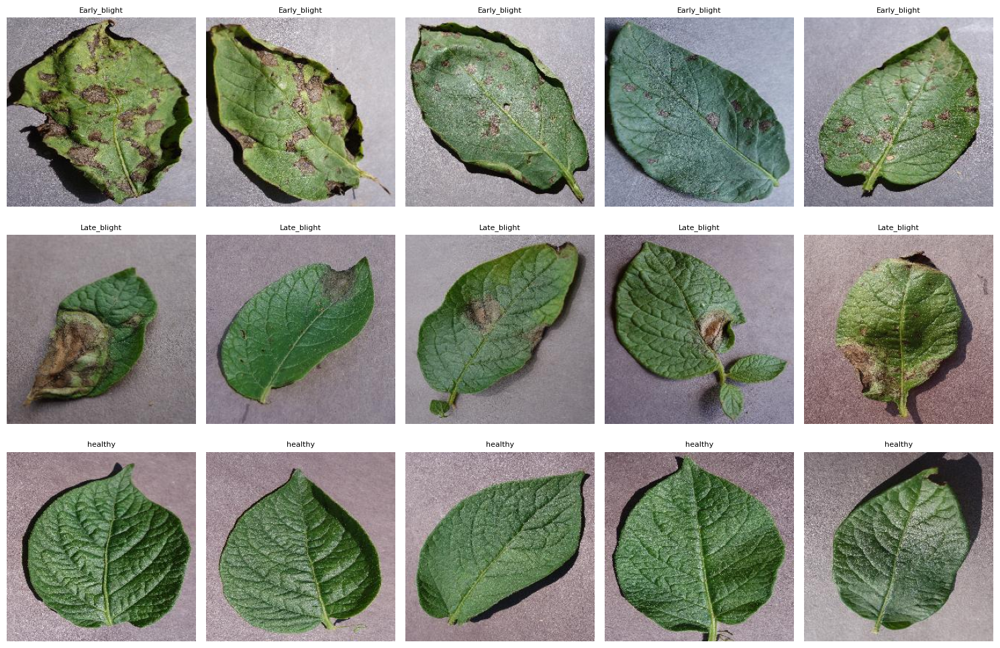

In [14]:
classes = ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

plt.figure(figsize=(15, 10))

img_count = 1

for cls in classes:
    class_path = os.path.join(dataset_dir, cls)
    images = os.listdir(class_path)

    for i in range(5):
        img_path = os.path.join(class_path, images[i])
        img = Image.open(img_path)

        plt.subplot(3, 5, img_count)
        plt.imshow(img)
        plt.title(cls.replace("Potato___", ""), fontsize=8)
        plt.axis("off")

        img_count += 1

plt.tight_layout()
plt.show()

# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">piechart and Barplot subplot</p>

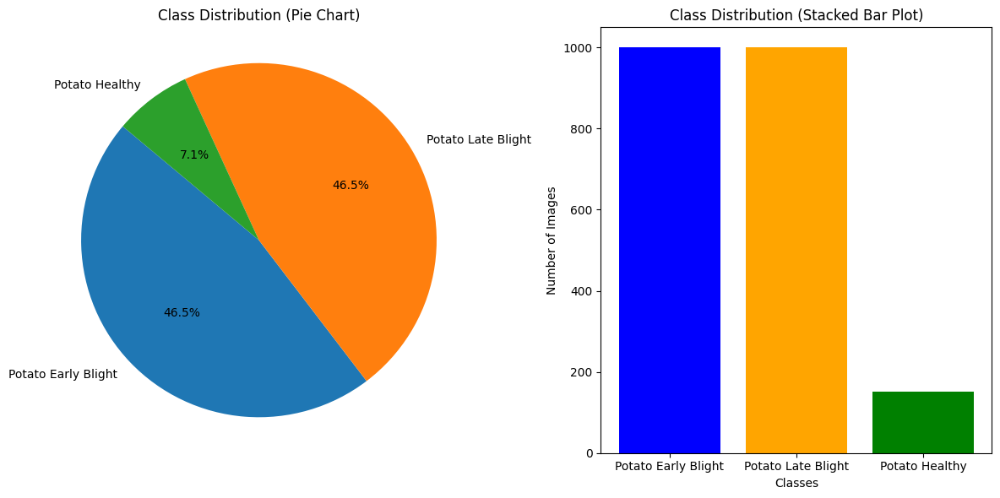

In [15]:
# Define the path to the dataset and the class folders
dataset_dir = "C:\\Users\\USER\\OneDrive\\Desktop\\Plant\\dataset\\PlantVillage"
class_dirs = ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
class_labels = ['Potato Early Blight', 'Potato Late Blight', 'Potato Healthy']

# Calculate number of images in each class
class_counts = []
for class_dir in class_dirs:
    class_path = os.path.join(dataset_dir, class_dir)
    num_images = len(os.listdir(class_path))
    class_counts.append(num_images)

# Calculate percentages for pie chart
total_images = sum(class_counts)
percentages = [(count / total_images) * 100 for count in class_counts]

# Create figure and subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# Pie chart
ax1.pie(percentages, labels=class_labels, autopct='%1.1f%%', startangle=140)
ax1.set_title('Class Distribution (Pie Chart)')
ax1.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

# Stacked bar plot
ax2.bar(class_labels, class_counts, color=['blue', 'orange', 'green'])
ax2.set_title('Class Distribution (Stacked Bar Plot)')
ax2.set_xlabel('Classes')
ax2.set_ylabel('Number of Images')

# Adjust layout
plt.tight_layout()

# Show plots
plt.show()


## **Observations:**
* As This is the plant village potato disease Dataset It consists of three classses such as Potato Early_blight, Potato Late_blight and the Potato Healthy.
* By creating the subplots piechart and barplot it is determined thatPotato Early blight and Potato late blight have the same percentage of images in this dataset i-e: of about 46.5 and the Potato Healthy have very less percentage of images in this dataset i-e: of about 7.1

# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">Data Preparation and Augmentation Setup</p>

Data augmentation is a technique used to artificially increase dataset size by applying transformations like rotation, flipping, zooming, and shifting on existing images. It helps prevent overfitting, improves generalization, and makes the model more robust to real-world variations in image data.

This part of the code is used to:

- Load and preprocess image data

- Apply data augmentation to training data

- Split dataset into training and validation sets

- Improve model generalization and performance

In [16]:
# Define the paths
base_dir = "C:\\Users\\USER\\OneDrive\\Desktop\\Plant\\dataset\\PlantVillage"

# Initialize ImageDataGenerator for training and validation sets
train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.efficientnet.preprocess_input,
    validation_split=0.2,  # Split 20% for validation
    horizontal_flip=True,
    zoom_range=0.3,
    shear_range=0.3,
    rotation_range=40,
    width_shift_range=0.3,
    height_shift_range=0.3,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.efficientnet.preprocess_input,
    validation_split=0.2
)

# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">Lets Load the Training and Validation Data</p>

This code is used to:

- Load images from the dataset directory
- Automatically assign labels based on folder names
- Resize images to required input size
- Convert data into batches for efficient training
- Split dataset into training and validation sets

In [17]:
# Load the training set
train_generator = train_datagen.flow_from_directory(
    base_dir,
    target_size=(300, 300),  # Adjusted target size for EfficientNetB3
    batch_size=16,
    class_mode='categorical',
    subset='training'
)

# Load the validation set
validation_generator = val_datagen.flow_from_directory(
    base_dir,
    target_size=(300, 300),  # Adjusted target size for EfficientNetB3
    batch_size=16,
    class_mode='categorical',
    subset='validation'
)


Found 1722 images belonging to 3 classes.


Found 430 images belonging to 3 classes.


# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">Lets Load and Finetune EfficientNetB3</p>

In [11]:
# Get class indices from the training generator
class_indices = train_generator.class_indices
class_labels = list(class_indices.keys())

# Calculate class weights
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)

class_weights_dict = dict(enumerate(class_weights))
print("Class weights:", class_weights_dict)

# Load the EfficientNetB3 model pre-trained on ImageNet
base_model = EfficientNetB3(weights='imagenet', include_top=False, input_shape=(300, 300, 3))

# Add custom layers on top of EfficientNetB3
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(3, activation='softmax')(x)  # Assuming 3 classes: Early_blight, Late_blight, healthy

# Define the complete model
model = Model(inputs=base_model.input, outputs=predictions)

# Freeze all layers of the base model
for layer in base_model.layers:
    layer.trainable = False

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

# Set up early stopping, model checkpoint, and learning rate reduction
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True, save_weights_only=False)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=15, min_lr=1e-6)
# Train the model with class weights and early stopping
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // validation_generator.batch_size,
    epochs=50,
    class_weight=class_weights_dict,
    callbacks=[early_stopping, checkpoint, reduce_lr]
)



Class weights: {0: np.float64(0.7175), 1: np.float64(0.7175), 2: np.float64(4.704918032786885)}
Epoch 1/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 550s 5s/step - accuracy: 0.7368 - loss: 0.6448 - val_accuracy: 0.8870 - val_loss: 0.3610 - learning_rate: 1.0000e-04
Epoch 2/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 38s 349ms/step - accuracy: 0.8750 - loss: 0.3589 - val_accuracy: 0.8822 - val_loss: 0.3666 - learning_rate: 1.0000e-04
Epoch 3/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 283s 3s/step - accuracy: 0.8822 - loss: 0.3080 - val_accuracy: 0.8822 - val_loss: 0.2962 - learning_rate: 1.0000e-04
Epoch 4/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 48s 441ms/step - accuracy: 0.9375 - loss: 0.2779 - val_accuracy: 0.8846 - val_loss: 0.2891 - learning_rate: 1.0000e-04
Epoch 5/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 304s 3s/step - accuracy: 0.9273 - loss: 0.2030 - val_accuracy: 0.8966 - val_loss: 0.2305 - learning_rate: 1.0000e-04
Epoch 6/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 48s 442ms/step - accuracy: 0.8750 - loss: 0.3389 - val_accuracy: 0.9014 - v

# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">Evaluation on Validation Data</p>

In [18]:
best_epoch = np.argmin(history.history['val_loss']) + 1

print("Best Epoch:", best_epoch)
print("Training Accuracy:", history.history['accuracy'][best_epoch - 1])
print("Validation Accuracy:", history.history['val_accuracy'][best_epoch - 1])
print("Training Loss:", history.history['loss'][best_epoch - 1])
print("Validation Loss:", history.history['val_loss'][best_epoch - 1])

Best Epoch: 7
Training Accuracy: 0.9378663301467896
Validation Accuracy: 0.9615384340286255
Training Loss: 0.17959444224834442
Validation Loss: 0.13668212294578552


In [ ]:
# Evaluate the model
loss, accuracy = model.evaluate(validation_generator)
print(f'Validation loss: {loss}')
print(f'Validation accuracy: {accuracy}')

27/27 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.9605 - loss: 0.1285
Validation loss: 0.12846273183822632
Validation accuracy: 0.960465133190155


# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">Training and Validation Accuracy and Loss</p>

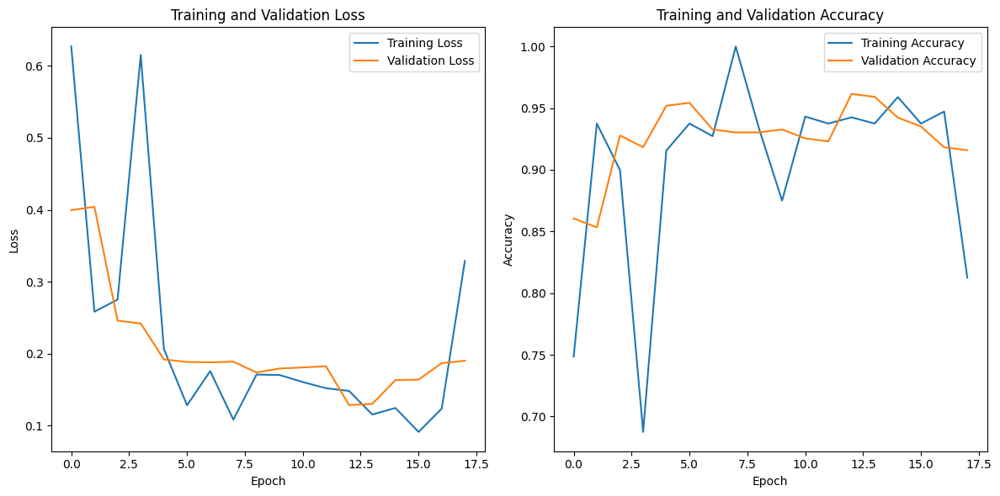

In [ ]:
# Plot training and validation loss
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

# Plot training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">Load the Saved Model</p>

In [ ]:
# Load the best saved model
model = load_model('best_model.keras')


Found 463 images belonging to 3 classes.
29/29 ━━━━━━━━━━━━━━━━━━━━ 73s 2s/step
Class indices: {'Potato___Early_blight': 0, 'Potato___Late_blight': 1, 'Potato___healthy': 2}

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

Early Blight     0.8158    0.9394    0.8732        33
 Late Blight     0.3613    0.8358    0.5045        67
     Healthy     0.9593    0.7135    0.8183       363

    accuracy                         0.7473       463
   macro avg     0.7121    0.8296    0.7320       463
weighted avg     0.8625    0.7473    0.7768       463


===== CONFUSION MATRIX =====
[[ 31   2   0]
 [  0  56  11]
 [  7  97 259]]


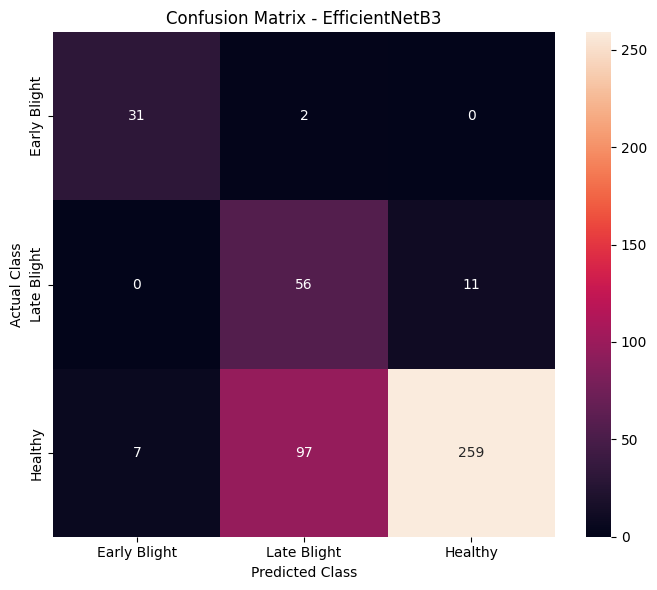

In [19]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix

# Load your already-trained model
model = load_model("best_model.keras")

# Test dataset
test_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.efficientnet.preprocess_input
)

test_generator = test_datagen.flow_from_directory(
    r"C:\Users\USER\OneDrive\Desktop\Plant\dataset\PlantVillage_Test",
    target_size=(300, 300),
    batch_size=16,
    class_mode="categorical",
    shuffle=False
)

# Predict test images
predictions = model.predict(test_generator)

y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

# IMPORTANT: use the actual generator class order
print("Class indices:", test_generator.class_indices)

class_names = [
    "Early Blight",
    "Late Blight",
    "Healthy"
]

# Classification report
print("\n===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("\n===== CONFUSION MATRIX =====")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - EfficientNetB3")

plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [3]:
best_epoch = np.argmin(history.history['val_loss']) + 1

print("Best Epoch:", best_epoch)

print("Training Accuracy:",
      history.history['accuracy'][best_epoch - 1])

print("Validation Accuracy:",
      history.history['val_accuracy'][best_epoch - 1])

print("Training Loss:",
      history.history['loss'][best_epoch - 1])

print("Validation Loss:",
      history.history['val_loss'][best_epoch - 1])

NameError: name 'history' is not defined

# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">Function to Load and Preprocess an Images</p>

In [16]:
def load_and_preprocess_image(img_path, target_size=(300, 300)):
    # Load the image
    img = load_img(img_path, target_size=target_size)
    # Convert the image to array
    img_array = img_to_array(img)
    # Expand dimensions to match the shape of model input
    img_array = np.expand_dims(img_array, axis=0)
    # Preprocess the image using the same function used in training
    img_array = tf.keras.applications.efficientnet.preprocess_input(img_array)
    return img_array


# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">Generating Predictions for Potato Disease Images</p>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 304ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 275ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 278ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

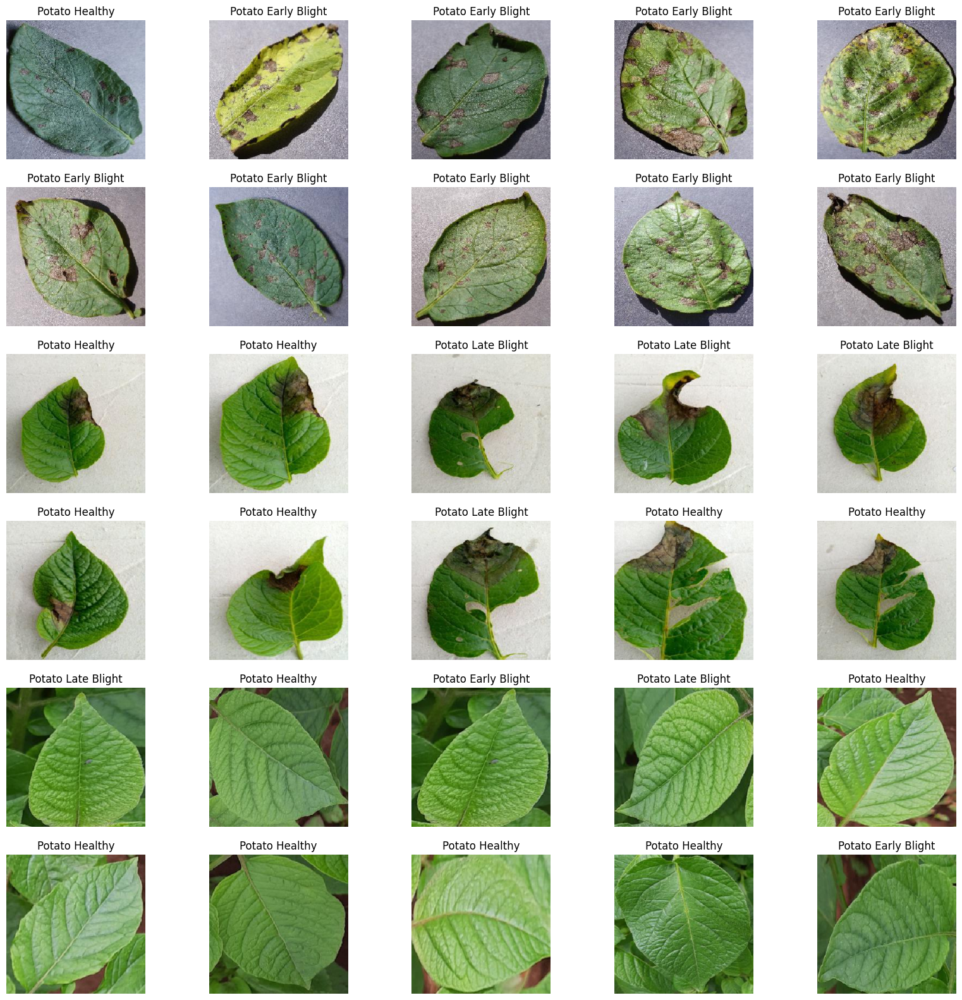

In [23]:
# Define the path to the dataset and the class folders
base_dir = 'C:\\Users\\USER\\OneDrive\\Desktop\\Plant\\dataset\\PlantVillage_Test'
classes = ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

# Collect some image paths from all folders
image_paths = []
for class_dir in classes:
    class_path = os.path.join(base_dir, class_dir)
    image_files = os.listdir(class_path)[:10]  # Change this to any number of images you want
    for image_file in image_files:
        image_paths.append(os.path.join(class_path, image_file))
        # Predict and display images with predicted labels
plt.figure(figsize=(20, 20))
for i, img_path in enumerate(image_paths):
    img_array = load_and_preprocess_image(img_path)
    prediction = model.predict(img_array)
    predicted_class = class_labels[np.argmax(prediction)]
    
    # Load the original image for display
    img = load_img(img_path, target_size=(300, 300))
    
    plt.subplot(6, 5, i + 1)
    plt.imshow(img)
    plt.title(predicted_class)
    plt.axis('off')

plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 984ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 772ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 614ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 613ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 367ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 376ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 378ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 360ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 323ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 316ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 340ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 444ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 360ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 399ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 366ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 418ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

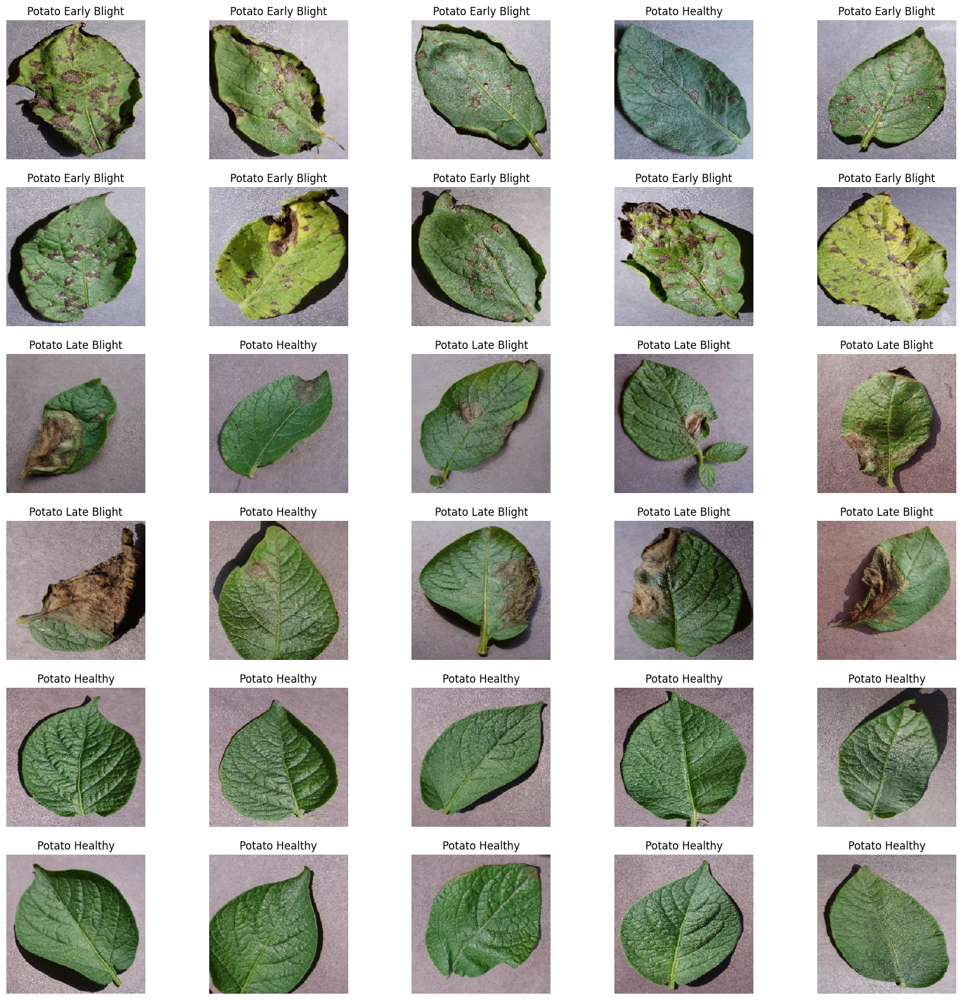

In [24]:
# Define the path to the dataset and the class folders
base_dir = 'C:\\Users\\USER\\OneDrive\\Desktop\\Plant\\dataset\\PlantVillage'
classes = ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

# Collect some image paths from all folders
image_paths = []
for class_dir in classes:
    class_path = os.path.join(base_dir, class_dir)
    image_files = os.listdir(class_path)[:10]  # Change this to any number of images you want
    for image_file in image_files:
        image_paths.append(os.path.join(class_path, image_file))
        # Predict and display images with predicted labels
plt.figure(figsize=(20, 20))
for i, img_path in enumerate(image_paths):
    img_array = load_and_preprocess_image(img_path)
    prediction = model.predict(img_array)
    predicted_class = class_labels[np.argmax(prediction)]
    
    # Load the original image for display
    img = load_img(img_path, target_size=(300, 300))
    
    plt.subplot(6, 5, i + 1)
    plt.imshow(img)
    plt.title(predicted_class)
    plt.axis('off')

plt.show()


# <p style="background-color: #54080b; color: gold; font-size: 90%; font-family: 'Lobster', cursive; text-align: center; border-radius: 15px 50px; border: 2px solid gold; padding: 20px 30px;">Conclusion</p>

* This is the plant village potato disease Dataset
* This Dataset is a comprehensive collection of images which is categorized into three distinct
* There are Total 2152 number of Images in Dataset
* The plant village contains 3 folders such as of Class Potato Early_blight, Potato Late_blight and Potato healthy
* The Class Potato Early_blight consists of 1000 number of Images
* The Class Potato Late_blight also consists of 1000 number of Images
* The Potato Healthy consists of 152 number of Images
* The Aim to take this Dataset is to explore the plant diseases which belongs to the classes such as the Potato late_blight, Potato Early_blight and also the healthy poato plants
* For this I firstly took the overview of the dataset in order to take a look how many number of images in each class has according to this dataset.
* Then I display the images of each class in order to take the insights about the dataset.
* 1722 images belonging to 3 classes are found in training dataset.
* 430 images belonging to 3 classes are found in validation dataset.
* Then I load and Finetune EfficientNetB3 and evlauate the results
* Then I Generate the predictions based on that model